Dimensões: (256, 256)
Número de dimensões: 2


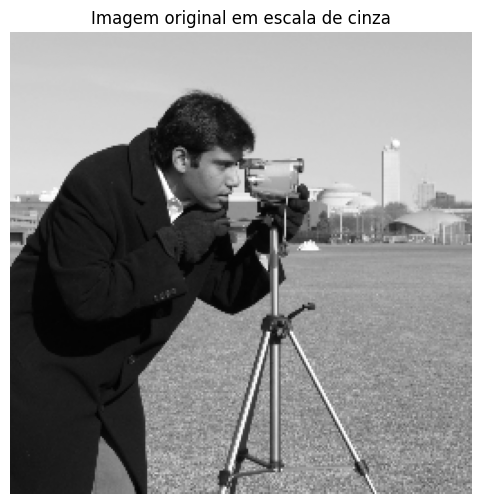

In [81]:
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
original = data.camera()
imagem = original[::2, ::2]

print("Dimensões:", imagem.shape)
print("Número de dimensões:", imagem.ndim)

plt.figure(figsize=(6, 6))
plt.imshow(imagem, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem original em escala de cinza")
plt.axis("off")
plt.show()

In [82]:
def convolucao_manual(imagem, kernel):
    imagem = np.asarray(imagem, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if imagem.ndim != 2 or kernel.ndim != 2:
        raise ValueError("A imagem e o kernel devem ser matrizes 2D.")

    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("As dimensões do kernel devem ser ímpares.")

    altura, largura = imagem.shape
    ph, pw = kh // 2, kw // 2
    imagem_pad = np.pad(imagem, ((ph, ph), (pw, pw)), mode="reflect")
    kernel_invertido = kernel[::-1, ::-1]
    resultado = np.zeros((altura, largura), dtype=np.float64)
    for i in range(kh):
        for j in range(kw):
            resultado += kernel_invertido[i, j] * imagem_pad[i:i + altura, j:j + largura]

    return resultado

In [83]:
def validar_tamanho(tamanho):
    if not isinstance(tamanho, (int, np.integer)) or tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser um inteiro positivo e ímpar.")


def preparar_imagem(imagem, tamanho):
    validar_tamanho(tamanho)
    imagem = np.asarray(imagem)
    if imagem.ndim != 2:
        raise ValueError("A imagem deve estar em escala de cinza (2D).")
    pad = tamanho // 2
    imagem_pad = np.pad(imagem, ((pad, pad), (pad, pad)), mode="reflect")
    return imagem, imagem_pad

In [84]:
def Media(imagem, tamanho=3):
    validar_tamanho(tamanho)
    kernel = np.ones((tamanho, tamanho), dtype=np.float64) / (tamanho * tamanho)
    resultado = convolucao_manual(imagem, kernel)
    return np.clip(np.rint(resultado), 0, 255).astype(np.uint8)

In [85]:
def Mediana(imagem, tamanho=3):
    imagem, imagem_pad = preparar_imagem(imagem, tamanho)
    altura, largura = imagem.shape
    resultado = np.empty_like(imagem)

    for i in range(altura):
        for j in range(largura):
            janela = imagem_pad[i:i + tamanho, j:j + tamanho]
            valores_ordenados = np.sort(janela, axis=None)
            resultado[i, j] = valores_ordenados[len(valores_ordenados) // 2]

    return resultado

In [86]:
def Moda(imagem, tamanho=3):
    imagem, imagem_pad = preparar_imagem(imagem, tamanho)
    altura, largura = imagem.shape
    resultado = np.empty_like(imagem)

    for i in range(altura):
        for j in range(largura):
            janela = imagem_pad[i:i + tamanho, j:j + tamanho].ravel()
            valores, contagens = np.unique(janela, return_counts=True)
            resultado[i, j] = valores[np.argmax(contagens)]

    return resultado

In [87]:
def Maximo(imagem, tamanho=3):
    imagem, imagem_pad = preparar_imagem(imagem, tamanho)
    altura, largura = imagem.shape
    resultado = np.empty_like(imagem)

    for i in range(altura):
        for j in range(largura):
            janela = imagem_pad[i:i + tamanho, j:j + tamanho]
            resultado[i, j] = np.max(janela)

    return resultado

In [88]:
TamanhoJanela = 3

imagem_media = Media(imagem, TamanhoJanela)
imagem_mediana = Mediana(imagem, TamanhoJanela)
imagem_moda = Moda(imagem, TamanhoJanela)
imagem_maximo = Maximo(imagem, TamanhoJanela)

print(f"Todos os filtros aplicados com janela {TamanhoJanela}x{TamanhoJanela}.")
print("Formato das imagens filtradas:", imagem_media.shape)

Todos os filtros aplicados com janela 3x3.
Formato das imagens filtradas: (256, 256)


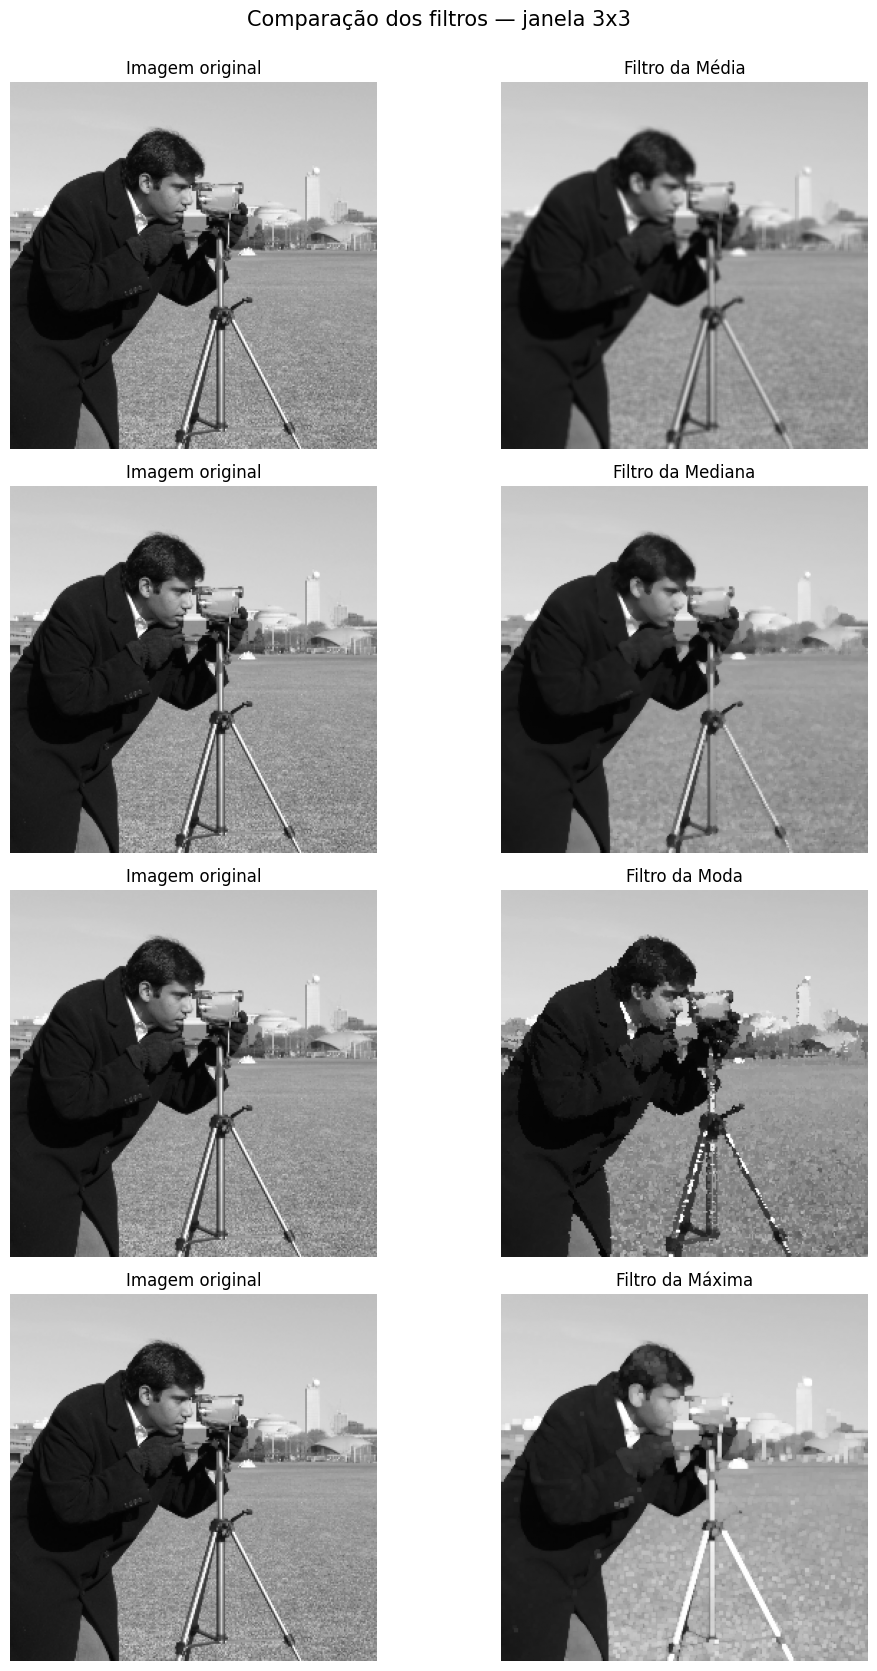

In [89]:
resultados = [("Filtro da Média", imagem_media),("Filtro da Mediana", imagem_mediana),("Filtro da Moda", imagem_moda),("Filtro da Máxima", imagem_maximo)]
fig, axes = plt.subplots(4, 2, figsize=(11, 17))
for i, (nome, imagem_filtrada) in enumerate(resultados):
    axes[i, 0].imshow(imagem, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title("Imagem original")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(imagem_filtrada, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(nome)
    axes[i, 1].axis("off")

fig.suptitle(f"Comparação dos filtros — janela {TamanhoJanela}x{TamanhoJanela}", fontsize=15)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()